# Praktikum 2.7: Diagnosis Bias-Variance
Dataset: Telco Customer Churn. Jalankan sel dari atas ke bawah (tekan **Shift+Enter** pada tiap sel).

## Langkah 1: Import library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

## Langkah 2: Muat dan siapkan data
Data diambil langsung dari internet, jadi tidak perlu mengunggah file CSV.

In [2]:
import os
# Baca dari folder data/ jika ada (repositori lokal); jika tidak (misalnya di Colab), ambil dari internet
lokal = "../data/Telco-Customer-Churn.csv"
url = lokal if os.path.exists(lokal) else "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("Ukuran data:", df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = pd.get_dummies(df, drop_first=True)

X = df.drop(columns="Churn")
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Data latih:", X_train.shape)

Ukuran data: (7043, 21)
Data latih: (5625, 30)


## Langkah 3: Praktikum 2.7 (kode dari buku)

In [3]:
# Bandingkan learning curve untuk max_depth berbeda
for depth in [1, 4, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5, train_sizes=np.linspace(0.1, 1.0, 6)
    )
    print(f"max_depth={depth}: train={train_scores.mean():.3f}, "
          f"val={val_scores.mean():.3f}")

max_depth=1: train=0.740, val=0.733


max_depth=4: train=0.806, val=0.783


max_depth=None: train=0.999, val=0.727


## Langkah 4 (tambahan): Grafik learning curve
Grafik ini bisa dilampirkan di laporan.

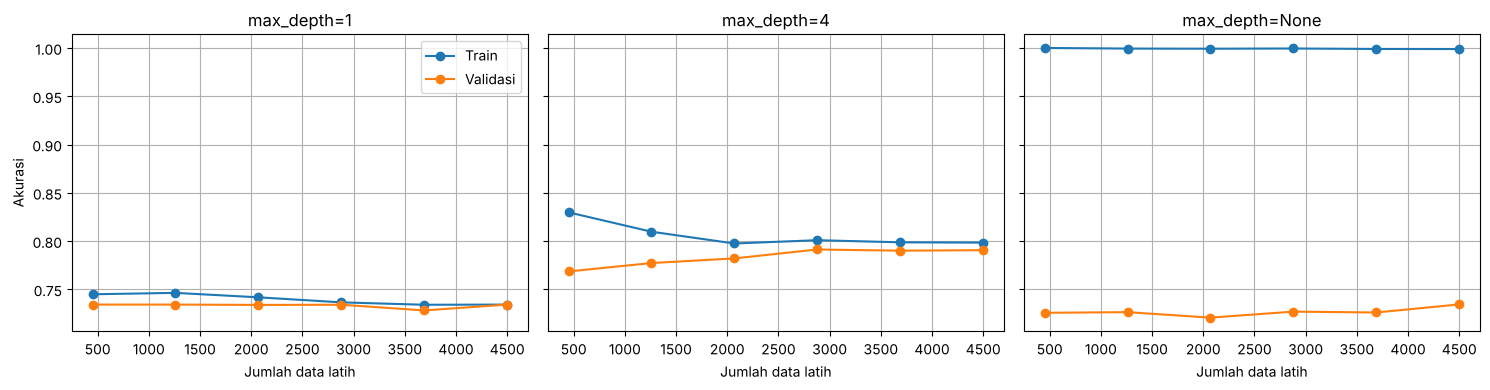

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, depth in zip(axes, [1, 4, None]):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    sizes, tr, va = learning_curve(
        model, X_train, y_train, cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6)
    )
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Train")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validasi")
    ax.set_title(f"max_depth={depth}")
    ax.set_xlabel("Jumlah data latih")
    ax.grid(True)
axes[0].set_ylabel("Akurasi")
axes[0].legend()
plt.tight_layout()
plt.show()

## Langkah 5: Diagnosis
Isi sendiri berdasarkan output di Langkah 3:

- **max_depth=1**: skor train dan validasi sama-sama rendah, gap kecil: **underfitting**
- **max_depth=4**: skor tinggi dan gap kecil: **seimbang**
- **max_depth=None**: train hampir 1,0 tetapi validasi jauh lebih rendah, gap besar: **overfitting**